# Task 3: Customer Segmentation Using RFM Analysis

**Goal:** use purchase history to score customers by Recency, Frequency, and Monetary value, group similar customers, and suggest a simple marketing action for each group.

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), a UK online retailer's transactions from December 2010 to December 2011. The original workbook is stored beside this notebook as `Online Retail.xlsx`.

This notebook follows the task directly: inspect and clean the sales records, calculate customer-level RFM measures, assign scores and segments, and summarize the results with charts. The code is kept in short steps so each calculation is easy to follow.

## 1. Load the data

Each row is an item on an invoice. An invoice can have several rows, so later we count **unique invoices** for Frequency rather than counting rows.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_excel("Online Retail.xlsx")

print("Rows and columns:", data.shape)
data.head()

Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Check the source records

Before calculating RFM, check missing customer IDs, cancellation invoices, non-positive quantities or prices, and exact duplicate rows. A row without a customer ID cannot be assigned to a customer. Cancellation and non-positive rows are not treated as purchases in this analysis.

In [2]:
data.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [3]:
data.duplicated().sum()

np.int64(5268)

## 3. Prepare valid sales

Remove exact duplicate records, rows without a customer ID, cancellation invoices (invoice numbers beginning with `C`), and rows with a quantity or unit price of zero or less. These decisions keep returns/cancellations from being counted as positive customer spend. The steps are shown separately so the number of rows removed is visible.

In [4]:
clean = data.drop_duplicates().copy()
after_duplicates = len(clean)

missing_customer = clean["CustomerID"].isna().sum()
clean = clean.dropna(subset=["CustomerID"])

cancelled = clean["InvoiceNo"].astype(str).str.startswith("C")
cancelled_rows = cancelled.sum()
clean = clean[~cancelled]

bad_quantity = clean["Quantity"] <= 0
bad_quantity_rows = bad_quantity.sum()
clean = clean[~bad_quantity]

bad_price = clean["UnitPrice"] <= 0
bad_price_rows = bad_price.sum()
clean = clean[~bad_price].copy()

clean["CustomerID"] = clean["CustomerID"].astype(int).astype(str)
clean["InvoiceNo"] = clean["InvoiceNo"].astype(str)
clean["Sales"] = clean["Quantity"] * clean["UnitPrice"]

cleaning_summary = pd.DataFrame({
    "Check": ["Original rows", "Exact duplicates removed", "Rows without CustomerID", "Cancellation rows", "Rows with quantity <= 0", "Rows with unit price <= 0", "Rows kept for RFM"],
    "Rows": [len(data), len(data) - after_duplicates, missing_customer, cancelled_rows, bad_quantity_rows, bad_price_rows, len(clean)]
})
cleaning_summary

,Check,Rows
0,Original rows,541909
1,Exact duplicates removed,5268
2,Rows without CustomerID,135037
3,Cancellation rows,8872
4,Rows with quantity <= 0,0
5,Rows with unit price <= 0,40
6,Rows kept for RFM,392692


## 4. Calculate Recency, Frequency, and Monetary value

- **Recency:** days since the customer's latest purchase. A smaller number means a more recent purchase.
- **Frequency:** number of distinct invoices for the customer.
- **Monetary:** total sales value (`Quantity × UnitPrice`) for the customer, in pounds sterling.

The reference date is one day after the latest valid purchase date, so the most recent purchase has a Recency of one day.

In [5]:
reference_date = clean["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
)

rfm["Recency"] = (reference_date - rfm["LastPurchase"]).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]].reset_index()

print("Reference date:", reference_date.date())
print("Customers analyzed:", len(rfm))
rfm.head()

Reference date: 2011-12-10
Customers analyzed: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


## 5. Score customers from 1 to 5

Use five equal-sized groups based on each measure. For Recency, the direction is reversed: fewer days since purchase earns a higher score. Higher Frequency and Monetary values earn higher scores. Ranking first lets `qcut` split tied values into five groups without changing the score direction.

In [6]:
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112


## 6. Create customer groups

The rules below use the RFM scores to make simple, explainable groups. The order matters: the most specific groups are checked first, and everyone else is placed in Potential Loyalists.

In [7]:
def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    if row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"
    if row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"
    if row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    if row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Hibernating"
    return "Potential Loyalists"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)
rfm["Segment"].value_counts()

Segment
Hibernating            1074
Champions               942
Potential Loyalists     843
At Risk                 661
Loyal Customers         508
Recent Customers        310
Name: count, dtype: int64

## 7. Summarize the segments

Compare the number of customers, average RFM behavior, and total customer spend in each segment. This makes the groups useful for prioritizing simple marketing actions.

In [8]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency_Days=("Recency", "mean"),
    Avg_Invoices=("Frequency", "mean"),
    Avg_Spend=("Monetary", "mean"),
    Total_Spend=("Monetary", "sum")
)

segment_summary["Customer_Share_%"] = segment_summary["Customers"] / len(rfm) * 100
segment_summary["Spend_Share_%"] = segment_summary["Total_Spend"] / rfm["Monetary"].sum() * 100
segment_summary.sort_values("Total_Spend", ascending=False).round(2)

,Customers,Avg_Recency_Days,Avg_Invoices,Avg_Spend,Total_Spend,Customer_Share_%,Spend_Share_%
Segment,,,,,,,
Champions,942,12.50,11.20,6091.24,5737952.12,21.72,64.56
Loyal Customers,508,37.21,5.12,1826.03,927623.75,11.71,10.44
At Risk,661,150.64,3.41,1246.46,823912.44,15.24,9.27
Potential Loyalists,843,38.97,1.85,867.95,731677.86,19.43,8.23
Hibernating,1074,216.68,1.10,487.71,523803.28,24.76,5.89
Recent Customers,310,18.10,1.25,458.84,142239.44,7.15,1.60


## 8. Visualize the RFM groups

These charts are the task's optional visualization bonus: one compares customer counts, one compares spend, and the heatmap shows the average R, F, and M scores by segment.

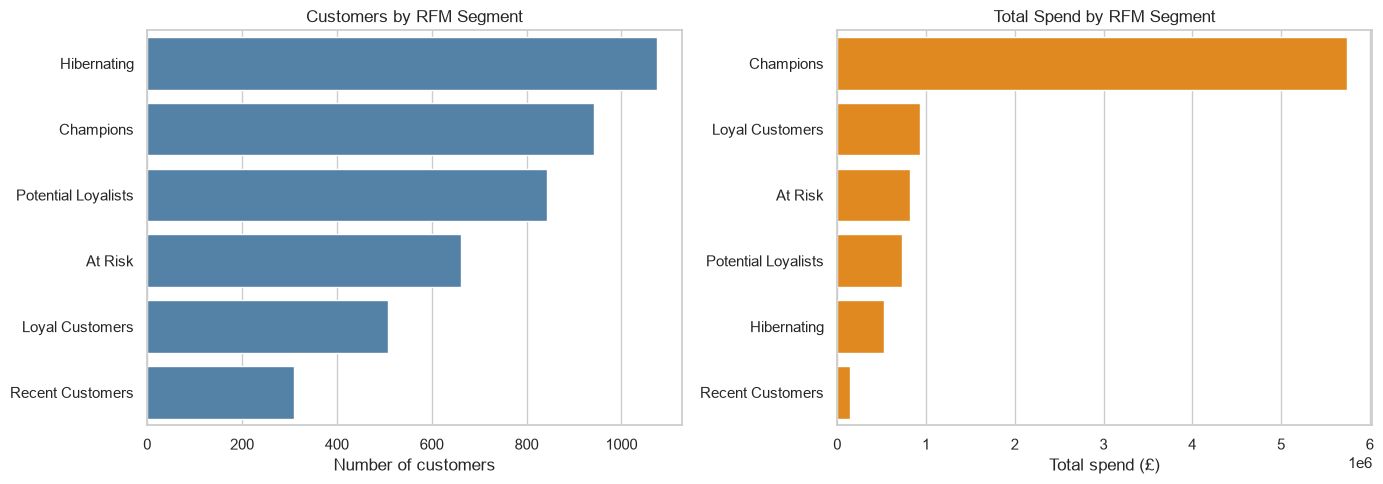

In [9]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

customer_order = segment_summary.sort_values("Customers", ascending=False).index
sns.barplot(data=segment_summary.reset_index(), x="Customers", y="Segment", order=customer_order, ax=axes[0], color="steelblue")
axes[0].set_title("Customers by RFM Segment")
axes[0].set_xlabel("Number of customers")
axes[0].set_ylabel("")

spend_order = segment_summary.sort_values("Total_Spend", ascending=False).index
sns.barplot(data=segment_summary.reset_index(), x="Total_Spend", y="Segment", order=spend_order, ax=axes[1], color="darkorange")
axes[1].set_title("Total Spend by RFM Segment")
axes[1].set_xlabel("Total spend (£)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

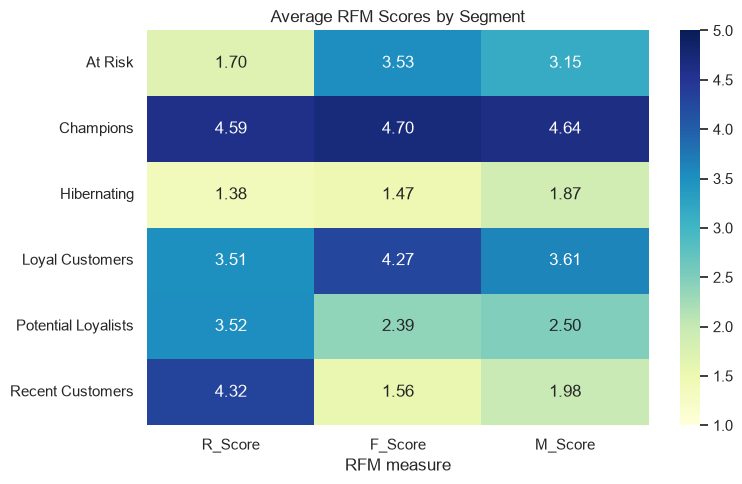

In [10]:
score_means = rfm.groupby("Segment")[["R_Score", "F_Score", "M_Score"]].mean()

plt.figure(figsize=(8, 5))
sns.heatmap(score_means, annot=True, cmap="YlGnBu", vmin=1, vmax=5, fmt=".2f")
plt.title("Average RFM Scores by Segment")
plt.xlabel("RFM measure")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 9. Simple marketing ideas

These are starting actions based on the behavior represented by each segment. A business should test campaigns and measure response before scaling them.

In [11]:
marketing_ideas = pd.DataFrame({
    "Segment": ["Champions", "Loyal Customers", "Recent Customers", "Potential Loyalists", "At Risk", "Hibernating"],
    "Marketing idea": [
        "Reward loyalty and offer early access to new products.",
        "Use a loyalty benefit or bundle to encourage another purchase.",
        "Welcome them and suggest related products for a second purchase.",
        "Send relevant product recommendations and a modest next-order offer.",
        "Reach out with a tailored reminder or limited-time incentive.",
        "Try a low-cost win-back message; stop if there is no response."
    ]
})
marketing_ideas

,Segment,Marketing idea
0,Champions,Reward loyalty and offer early access to new p...
1,Loyal Customers,Use a loyalty benefit or bundle to encourage a...
2,Recent Customers,Welcome them and suggest related products for ...
3,Potential Loyalists,Send relevant product recommendations and a mo...
4,At Risk,Reach out with a tailored reminder or limited-...
5,Hibernating,Try a low-cost win-back message; stop if there...


## 10. What the analysis tells us

RFM turns invoice history into a customer-level view: how recently each customer bought, how often they returned, and how much they spent. The segment summary and charts show which groups are largest and which account for the most spend. These are descriptive results from a one-year dataset; they do not predict future purchases or prove why customers stopped buying.

**Next step:** use the segment summary above to choose a small campaign for one group, then compare customer response and repeat purchases.